# 11 — Fine-tuning dos ramos e treino da camada de fusão (dados in situ)

Segue a seção 3.3.2, nas três etapas:

1. **Fine-tuning da CNN**: os pesos pré-treinados no MIMII (notebook 03 v3) são mantidos e a saída binária é **substituída pela saída de quatro níveis de anomalia acústica** (0 a 3). Taxa de aprendizado reduzida.
2. **Fine-tuning do LSTM**: o modelo pré-treinado no Bristol (notebook 04) é ajustado com as janelas in situ (nível térmico pelo termo-higrômetro). Taxa de aprendizado reduzida.
3. **Camada de fusão**: com os dois ramos **congelados**, treina-se só uma camada densa que recebe as 4 probabilidades do LSTM e a média das 4 probabilidades da CNN nas 10 últimas janelas de 1 s, e decide a classe (Normal, Atenção, Crítico, Falha).

Em todas as etapas: entropia cruzada ponderada pela frequência inversa das classes e parada antecipada pela perda de validação. **Divisão por sessão**, pela coluna `papel` do `sessoes.csv`: as sessões de `teste` não são lidas aqui (só no notebook 12).

Antes do treino, a célula 4b verifica se os níveis acústicos têm assinatura própria e quanto o BME280 difere do termo-higrômetro. No fim, a CNN é quantizada em int8 (calibração estratificada com até 100 janelas de cada nível, densas por tensor).

**Saídas** em `dissertacao_tinyml/modelos/insitu/`.

In [2]:
# 1. Ambiente e caminhos
import os, sys, json, subprocess, importlib.util
if importlib.util.find_spec("tensorflow") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tensorflow"], check=True)
import numpy as np, pandas as pd, tensorflow as tf, matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/dissertacao_tinyml"
except ImportError:
    BASE = os.environ.get("BASE_TINYML", "dissertacao_tinyml")
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter
CONJUNTO = os.environ.get("CONJUNTO_TINYML", "coleta_sim")   # "coleta_sim" = sessões sintéticas (notebook 07b) | "coleta" = dados do nó
CONJUNTO = "coleta_sim"
SIM = CONJUNTO != "coleta"
print("Conjunto de dados:", CONJUNTO)
COLETA, ROT = f"{BASE}/{CONJUNTO}", f"{BASE}/{CONJUNTO}/rotulado"
CNN0, LSTM0, SAIDA = f"{BASE}/modelos/cnn_v3", f"{BASE}/modelos/lstm", f"{BASE}/modelos/" + ("sim" if SIM else "insitu")
os.makedirs(SAIDA, exist_ok=True)

Mounted at /content/drive
Conjunto de dados: coleta_sim


In [3]:
# 2. Parâmetros
SEMENTE = 0
HP = {"lr_cnn": 1e-4, "lr_lstm": 1e-4, "lr_fusao": 1e-2, "lote": 64, "epocas": 50, "epocas_fusao": 300, "paciencia": 8}
MAX_NORMAL_SESSAO = 4000     # janelas de áudio de nível 0 sorteadas por sessão (as anômalas entram todas)
tf.keras.utils.set_random_seed(SEMENTE); rng = np.random.default_rng(SEMENTE)

In [4]:
# 3. Rótulos e matriz da Figura 5 (iguais aos do notebook 10)
# ===== Rotulação das sessões de eventos (seção 3.3.1 e Figura 5) =====
TIPOS = ["termico", "desbalanceamento", "obstrucao", "combinado"]
ACUSTICOS = {"desbalanceamento", "obstrucao", "combinado"}     # o tipo térmico não altera o nível acústico
TERMICOS = {"termico", "combinado"}
NOMES_CLASSE = ["Normal", "Atenção", "Crítico", "Falha"]

def classe_termica(t):
    t = np.asarray(t, dtype=float)
    return np.select([t > 35.0, t > 32.0, t > 27.0], [3, 2, 1], 0)

def classe_fusao_regra(nt, na):
    """Figura 5: prevalece o mais severo; térmico 2 com acústico >= 1 vira Falha; nível 3 em qualquer ramo = Falha."""
    nt, na = np.asarray(nt), np.asarray(na)
    c = np.maximum(nt, na)
    c = np.where((nt == 2) & (na >= 1), 3, c)
    return np.where((nt == 3) | (na == 3), 3, c).astype(int)

def eventos_da_sessao(evt, planilha, sessao):
    """Junta os pares início/fim do EVT.CSV com a planilha (tipo, nível, fundo) pelo número do evento."""
    e = evt[evt.evento > 0]
    ini = e[e.tipo == "inicio"].set_index("evento").amostra
    fim = e[e.tipo == "fim"].set_index("evento").amostra
    ev = pd.DataFrame({"amostra_ini": ini, "amostra_fim": fim}).reset_index()
    p = planilha[planilha.sessao == sessao].copy()
    problemas = []
    if ev.amostra_fim.isna().any():
        problemas.append(f"eventos sem fim no EVT.CSV: {ev[ev.amostra_fim.isna()].evento.tolist()}")
    if len(ev) != len(p):
        problemas.append(f"EVT.CSV tem {len(ev)} eventos e a planilha tem {len(p)} para {sessao}")
    ev = ev.merge(p[["evento", "tipo", "nivel", "fundo"]], on="evento", how="left")
    if ev.tipo.isna().any():
        problemas.append(f"eventos sem linha na planilha: {ev[ev.tipo.isna()].evento.tolist()}")
    return ev, problemas

def rotulos_acusticos(n_jan, ev, fs, transicao_s):
    """Nível acústico de cada janela de 1 s: nível do evento (tipos acústicos) ou 0; -1 = janela descartada
    por estar a menos de transicao_s de uma marcação. Também devolve o número do evento de cada janela (0 = fora)."""
    ini = np.arange(n_jan) * fs; fim = ini + fs
    y = np.zeros(n_jan, int); evid = np.zeros(n_jan, int)
    marg = int(transicao_s * fs)
    for _, e in ev.iterrows():
        a, b = int(e.amostra_ini), int(e.amostra_fim)
        dentro = (ini >= a) & (fim <= b)
        evid[dentro] = e.evento
        if e.tipo in ACUSTICOS: y[dentro] = int(e.nivel)
        for m in (a, b):                                   # janelas perto de uma marcação
            y[(fim > m - marg) & (ini < m + marg)] = -1
    return y, evid

def referencia_10s(termo, inicio_real, blocos, offset_s=0.0, max_lacuna_s=60):
    """Temperatura do termo-higrômetro interpolada na grade de 10 s do áudio (NaN onde não há referência)."""
    if termo is None or not len(termo):
        return np.full(len(blocos), np.nan)
    s = (pd.to_datetime(termo.horario) - pd.Timestamp(inicio_real)).dt.total_seconds().values + offset_s
    t = termo.temp_ref.values.astype(float)
    ordem = np.argsort(s); s, t = s[ordem], t[ordem]
    grade = np.asarray(blocos) * 10.0 + 5.0                # centro de cada bloco de 10 s do áudio
    ref = np.interp(grade, s, t, left=np.nan, right=np.nan)
    pos = np.searchsorted(s, grade)
    viz = np.minimum(np.abs(grade - s[np.clip(pos - 1, 0, len(s) - 1)]), np.abs(s[np.clip(pos, 0, len(s) - 1)] - grade))
    ref[viz > max_lacuna_s] = np.nan                        # longe de qualquer leitura: sem referência
    return ref


In [5]:
# 4. Leitura das sessões rotuladas (sem as de teste) e normalização pela linha de base acústica (base.csv)
SESSOES = pd.read_csv(f"{COLETA}/sessoes.csv", dtype=str).fillna("")
SESSOES = SESSOES[SESSOES.papel.isin(["treino", "validacao"])]
if SIM:   # proteção: com o conjunto sintético, só entram sessões geradas pelo 07b (SIMnnn)
    _fora = [s for s in SESSOES.sessao if not str(s).startswith("SIM")]
    assert not _fora, f"sessoes.csv de {CONJUNTO} contém sessões que não são do 07b: {_fora}"
print("Sessões lidas:", SESSOES.sessao.tolist())
b = pd.read_csv(f"{COLETA}/linha_de_base/base.csv")
MU, SD = b.media.values.astype(np.float32), b.desvio.values.astype(np.float32)
D = {}
for _, sx in SESSOES.iterrows():
    f = f"{ROT}/{sx.sessao}.npz"
    if not os.path.exists(f): print("Sem arquivo rotulado (rode o notebook 10):", sx.sessao); continue
    D[sx.sessao] = dict(np.load(f)); D[sx.sessao]["papel"] = sx.papel
print({s: d["papel"] for s, d in D.items()})
assert any(d["papel"] == "treino" for d in D.values()) and any(d["papel"] == "validacao" for d in D.values())

def z(X): return ((X.astype(np.float32) - MU) / SD)[..., None]

def conjunto_cnn(papel):
    X, y = [], []
    for s, d in D.items():
        if d["papel"] != papel: continue
        ya = d["ya"]; idx_a = np.where(ya > 0)[0]; idx_n = np.where(ya == 0)[0]
        if len(idx_n) > MAX_NORMAL_SESSAO: idx_n = rng.choice(idx_n, MAX_NORMAL_SESSAO, replace=False)
        idx = np.sort(np.concatenate([idx_a, idx_n]))
        X.append(z(d["Xc"][idx])); y.append(ya[idx])
    return np.concatenate(X), np.concatenate(y)
Xc_tr, yc_tr = conjunto_cnn("treino"); Xc_va, yc_va = conjunto_cnn("validacao")
print("CNN  treino:", np.bincount(yc_tr, minlength=4), " validação:", np.bincount(yc_va, minlength=4))

Sessões lidas: ['SIM001', 'SIM002', 'SIM003', 'SIM004', 'SIM005']
{'SIM001': 'treino', 'SIM002': 'treino', 'SIM003': 'treino', 'SIM004': 'treino', 'SIM005': 'validacao'}
CNN  treino: [16000  4860  4860  4860]  validação: [4000 1620 1620 1620]


Distância média entre espectros médios dos níveis (z, média dos 40 filtros):
  nível 0 × nível 1: 0.298
  nível 0 × nível 2: 0.815
  nível 0 × nível 3: 1.743
  nível 1 × nível 2: 0.518
  nível 1 × nível 3: 1.445
  nível 2 × nível 3: 0.928
  Distâncias próximas de zero entre 1, 2 e 3 indicam níveis sem assinatura acústica própria.
BME280 − termo-higrômetro (todas as janelas): média +0.20 °C | p5 -0.47 | p95 +0.86
BME280 − termo-higrômetro (referência > 27 °C): média +0.32 °C | p5 -1.60 | p95 +2.26
Diferenças grandes acima de 27 °C explicam confusões do LSTM entre classes térmicas.


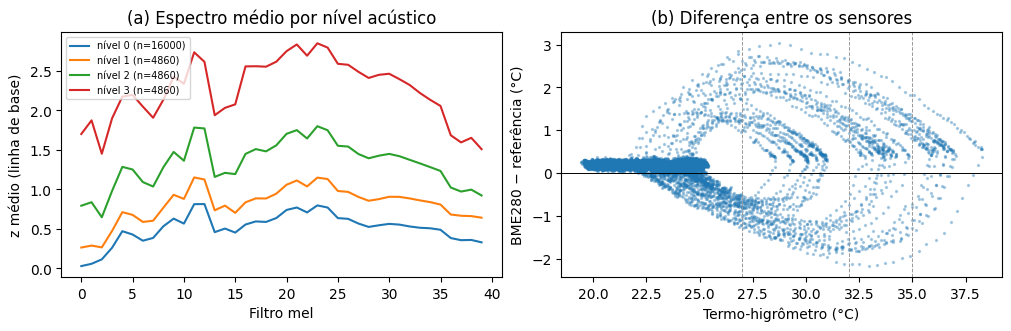

In [6]:
# 4b. Diagnóstico dos dados antes do treino
# (a) Os níveis acústicos são distinguíveis? Espectro médio (normalizado pela linha de base) por nível, no treino.
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
medias = {}
for c in range(4):
    sel = yc_tr == c
    if sel.any():
        medias[c] = Xc_tr[sel, ..., 0].mean(axis=(0, 1))
        ax[0].plot(medias[c], label=f"nível {c} (n={int(sel.sum())})")
ax[0].set_xlabel("Filtro mel"); ax[0].set_ylabel("z médio (linha de base)"); ax[0].legend(fontsize=7)
ax[0].set_title("(a) Espectro médio por nível acústico")
print("Distância média entre espectros médios dos níveis (z, média dos 40 filtros):")
for a in medias:
    for b in medias:
        if a < b: print(f"  nível {a} × nível {b}: {np.abs(medias[a] - medias[b]).mean():.3f}")
print("  Distâncias próximas de zero entre 1, 2 e 3 indicam níveis sem assinatura acústica própria.")

# (b) BME280 (entrada do LSTM) × termo-higrômetro (rótulo) nas mesmas janelas de 10 s
dif = []
for s, d in D.items():
    r, b_ = d["temp_ref"], d["temp_bme"]
    ok = ~np.isnan(r) & ~np.isnan(b_)
    if ok.any(): dif.append(pd.DataFrame({"sessao": s, "ref": r[ok], "dif": (b_ - r)[ok]}))
if dif:
    dif = pd.concat(dif)
    for nome, q in [("todas as janelas", dif), ("referência > 27 °C", dif[dif.ref > 27])]:
        if len(q): print(f"BME280 − termo-higrômetro ({nome}): média {q.dif.mean():+.2f} °C | p5 {q.dif.quantile(.05):+.2f} | p95 {q.dif.quantile(.95):+.2f}")
    ax[1].scatter(dif.ref, dif.dif, s=2, alpha=0.3)
    for L in (27, 32, 35): ax[1].axvline(L, color="0.6", ls="--", lw=0.7)
    ax[1].axhline(0, color="k", lw=0.7)
    ax[1].set_xlabel("Termo-higrômetro (°C)"); ax[1].set_ylabel("BME280 − referência (°C)")
    ax[1].set_title("(b) Diferença entre os sensores")
    print("Diferenças grandes acima de 27 °C explicam confusões do LSTM entre classes térmicas.")
plt.savefig(f"{SAIDA}/diagnostico_dados.png", dpi=150); plt.show()

In [7]:
# 5. Etapa 1: fine-tuning da CNN com saída de quatro níveis acústicos
def pesos(y):
    c = np.bincount(y, minlength=4); return {k: len(y) / (np.count_nonzero(c) * n) for k, n in enumerate(c) if n > 0}
semente_cnn = json.load(open(f"{CNN0}/cnn_int8_quantizacao.json"))["semente"]
base_cnn = tf.keras.models.load_model(f"{CNN0}/cnn_semente{semente_cnn}.keras")
sai4 = tf.keras.layers.Dense(4, activation="softmax", name="saida")(base_cnn.get_layer("densa").output)
cnn = tf.keras.Model(base_cnn.input, sai4, name="cnn2d_insitu")
cnn.compile(optimizer=tf.keras.optimizers.Adam(HP["lr_cnn"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
parada = lambda: tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=HP["paciencia"], restore_best_weights=True)
h_cnn = cnn.fit(Xc_tr, yc_tr, validation_data=(Xc_va, yc_va), epochs=HP["epocas"], batch_size=HP["lote"],
                class_weight=pesos(yc_tr), callbacks=[parada()], verbose=2)
pc_va = cnn.predict(Xc_va, verbose=0).argmax(1)
print("CNN validação — F1 macro:", round(f1_score(yc_va, pc_va, average="macro"), 4))
print(confusion_matrix(yc_va, pc_va, labels=[0, 1, 2, 3]))
cnn.save(f"{SAIDA}/cnn_insitu.keras")

Epoch 1/50
478/478 - 22s - 46ms/step - accuracy: 0.3061 - loss: 1.4405 - val_accuracy: 0.4870 - val_loss: 1.1672
Epoch 2/50
478/478 - 24s - 51ms/step - accuracy: 0.5518 - loss: 1.0400 - val_accuracy: 0.5416 - val_loss: 0.9666
Epoch 3/50
478/478 - 20s - 41ms/step - accuracy: 0.6007 - loss: 0.8762 - val_accuracy: 0.5783 - val_loss: 0.8711
Epoch 4/50
478/478 - 20s - 42ms/step - accuracy: 0.6284 - loss: 0.7933 - val_accuracy: 0.6053 - val_loss: 0.8144
Epoch 5/50
478/478 - 20s - 42ms/step - accuracy: 0.6487 - loss: 0.7326 - val_accuracy: 0.6340 - val_loss: 0.7626
Epoch 6/50
478/478 - 19s - 40ms/step - accuracy: 0.6665 - loss: 0.6890 - val_accuracy: 0.6542 - val_loss: 0.7277
Epoch 7/50
478/478 - 19s - 40ms/step - accuracy: 0.6786 - loss: 0.6589 - val_accuracy: 0.6635 - val_loss: 0.7035
Epoch 8/50
478/478 - 21s - 45ms/step - accuracy: 0.6878 - loss: 0.6353 - val_accuracy: 0.6754 - val_loss: 0.6841
Epoch 9/50
478/478 - 20s - 41ms/step - accuracy: 0.6964 - loss: 0.6168 - val_accuracy: 0.6835 - 

In [8]:
# 6. Etapa 2: fine-tuning do LSTM (nível térmico pela referência)
FAIXAS = {"temp": (10.0, 45.0), "umid": (0.0, 100.0), "dpress": (-5.0, 5.0)}
def atributos(v):
    v = np.asarray(v, np.float32); dp = v[..., 2] - v[..., 2].mean(axis=-1, keepdims=True)
    cols = [v[..., 0], v[..., 1], dp]
    return np.stack([np.clip((c - lo) / (hi - lo), 0, 1) for c, (lo, hi) in zip(cols, FAIXAS.values())], -1).astype(np.float32)
def conjunto_lstm(papel):
    X = [d["Xl"] for d in D.values() if d["papel"] == papel and len(d["Xl"])]
    y = [d["yl"] for d in D.values() if d["papel"] == papel and len(d["Xl"])]
    return atributos(np.concatenate(X)), np.concatenate(y)
Xl_tr, yl_tr = conjunto_lstm("treino"); Xl_va, yl_va = conjunto_lstm("validacao")
print("LSTM treino:", np.bincount(yl_tr, minlength=4), " validação:", np.bincount(yl_va, minlength=4))
semente_l = json.load(open(f"{LSTM0}/lstm_int8_quantizacao.json"))["semente"]
lstm = tf.keras.models.load_model(f"{LSTM0}/lstm_semente{semente_l}.keras")
lstm.compile(optimizer=tf.keras.optimizers.Adam(HP["lr_lstm"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_lstm = lstm.fit(Xl_tr, yl_tr, validation_data=(Xl_va, yl_va), epochs=HP["epocas"], batch_size=HP["lote"],
                  class_weight=pesos(yl_tr), callbacks=[parada()], verbose=2)
pl_va = lstm.predict(Xl_va, verbose=0).argmax(1)
print("LSTM validação — F1 macro:", round(f1_score(yl_va, pl_va, average="macro"), 4))
print(confusion_matrix(yl_va, pl_va, labels=[0, 1, 2, 3]))
lstm.save(f"{SAIDA}/lstm_insitu.keras")

LSTM treino: [13819   770   298   150]  validação: [1699  273  114   56]
Epoch 1/50
235/235 - 6s - 28ms/step - accuracy: 0.9725 - loss: 2.1323 - val_accuracy: 0.9421 - val_loss: 0.7535
Epoch 2/50
235/235 - 4s - 15ms/step - accuracy: 0.9751 - loss: 1.8127 - val_accuracy: 0.9482 - val_loss: 0.7394
Epoch 3/50
235/235 - 3s - 13ms/step - accuracy: 0.9767 - loss: 1.6193 - val_accuracy: 0.9496 - val_loss: 0.7271
Epoch 4/50
235/235 - 6s - 24ms/step - accuracy: 0.9775 - loss: 1.4464 - val_accuracy: 0.9482 - val_loss: 0.7011
Epoch 5/50
235/235 - 5s - 19ms/step - accuracy: 0.9785 - loss: 1.2200 - val_accuracy: 0.9514 - val_loss: 0.6385
Epoch 6/50
235/235 - 3s - 13ms/step - accuracy: 0.9798 - loss: 0.9811 - val_accuracy: 0.9542 - val_loss: 0.5809
Epoch 7/50
235/235 - 3s - 13ms/step - accuracy: 0.9812 - loss: 0.7802 - val_accuracy: 0.9566 - val_loss: 0.5284
Epoch 8/50
235/235 - 3s - 13ms/step - accuracy: 0.9818 - loss: 0.5894 - val_accuracy: 0.9589 - val_loss: 0.4843
Epoch 9/50
235/235 - 5s - 21ms/

In [9]:
# 7. Etapa 3: camada de fusão com os ramos congelados
def entradas_fusao(d, modelo_cnn=cnn):
    """Para cada decisão: [4 prob. do LSTM, média das 4 prob. da CNN nas 10 janelas de 1 s] e a classe-alvo."""
    if not len(d["dec_y"]): return np.zeros((0, 8), np.float32), np.zeros(0, int)
    jan = np.unique(np.concatenate([np.arange(j - 9, j + 1) for j in d["dec_j"]]))
    pc = np.zeros((len(d["ya"]), 4), np.float32)
    pc[jan] = modelo_cnn.predict(z(d["Xc"][jan]), batch_size=256, verbose=0)
    pc10 = np.stack([pc[j - 9:j + 1].mean(0) for j in d["dec_j"]])
    pl = lstm.predict(atributos(d["Xl"][d["dec_l"]]), batch_size=256, verbose=0)
    return np.concatenate([pl, pc10], 1).astype(np.float32), d["dec_y"].astype(int)
F = {p: [entradas_fusao(d) for d in D.values() if d["papel"] == p] for p in ["treino", "validacao"]}
Xf_tr, yf_tr = np.concatenate([a for a, _ in F["treino"]]), np.concatenate([b for _, b in F["treino"]])
Xf_va, yf_va = np.concatenate([a for a, _ in F["validacao"]]), np.concatenate([b for _, b in F["validacao"]])
print("Fusão treino:", np.bincount(yf_tr, minlength=4), " validação:", np.bincount(yf_va, minlength=4))
ent = tf.keras.Input((8,), name="prob_ramos")
fusao = tf.keras.Model(ent, tf.keras.layers.Dense(4, activation="softmax", name="fusao")(ent), name="fusao")
fusao.compile(optimizer=tf.keras.optimizers.Adam(HP["lr_fusao"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
fusao.fit(Xf_tr, yf_tr, validation_data=(Xf_va, yf_va), epochs=HP["epocas_fusao"], batch_size=HP["lote"],
          class_weight=pesos(yf_tr), callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)], verbose=0)
pf_va = fusao.predict(Xf_va, verbose=0).argmax(1)
regra_va = classe_fusao_regra(Xf_va[:, :4].argmax(1), Xf_va[:, 4:].argmax(1))
print("Validação — F1 macro: fusão treinada", round(f1_score(yf_va, pf_va, average="macro"), 4),
      "| fusão por regra (Figura 5)", round(f1_score(yf_va, regra_va, average="macro"), 4))
W, bias = fusao.get_layer("fusao").get_weights()
json.dump({"W": W.tolist(), "b": bias.tolist(), "entrada": "p_lstm[0..3], media10_p_cnn[0..3]"},
          open(f"{SAIDA}/fusao.json", "w"), indent=1)
fusao.save(f"{SAIDA}/fusao.keras")
print("Parâmetros da camada de fusão:", fusao.count_params())

Fusão treino: [12416  1015   585   589]  validação: [1235  353  201  209]
Validação — F1 macro: fusão treinada 0.8938 | fusão por regra (Figura 5) 0.8601
Parâmetros da camada de fusão: 36


In [10]:
# 8. Quantização int8 da CNN in situ (100 janelas do treino; densas por tensor) e concordância com a float32
# calibração estratificada: até 100 janelas de cada nível acústico do treino
idx_rep = np.concatenate([rng.choice(np.where(yc_tr == c)[0], min(100, int((yc_tr == c).sum())), replace=False)
                          for c in range(4) if (yc_tr == c).any()])
conv = tf.lite.TFLiteConverter.from_keras_model(cnn)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = lambda: ([Xc_tr[i:i + 1]] for i in idx_rep)   # 1 janela por passo
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8; conv.inference_output_type = tf.int8
conv._experimental_disable_per_channel_quantization_for_dense_layers = True
tfl = conv.convert(); open(f"{SAIDA}/cnn_insitu_int8.tflite", "wb").write(tfl)
it = Interpreter(model_content=tfl); it.allocate_tensors()
e_, s_ = it.get_input_details()[0], it.get_output_details()[0]
(se, ze), (ss, zs) = e_["quantization"], s_["quantization"]
def prob_int8(X):
    out = np.zeros((len(X), 4), np.float32)
    for i in range(len(X)):
        it.set_tensor(e_["index"], np.clip(np.round(X[i:i + 1] / se + ze), -128, 127).astype(np.int8)); it.invoke()
        out[i] = (it.get_tensor(s_["index"])[0].astype(np.float32) - zs) * ss
    return out
p8 = prob_int8(Xc_va); p32 = cnn.predict(Xc_va, verbose=0)
print(f"int8: {len(tfl) / 1024:.1f} KB | janelas de calibração: {len(idx_rep)}")
print(f"Concordância float32 × int8 na validação — 4 níveis: {100 * (p8.argmax(1) == p32.argmax(1)).mean():.2f}% | "
      f"normal × anômalo: {100 * ((p8.argmax(1) > 0) == (p32.argmax(1) > 0)).mean():.2f}%")
print("F1 macro na validação — float32:", round(f1_score(yc_va, p32.argmax(1), average="macro"), 4),
      "| int8:", round(f1_score(yc_va, p8.argmax(1), average="macro"), 4))
json.dump({"semente_pretreino": int(semente_cnn), "quantizacao": {"entrada": [float(se), float(ze)], "saida": [float(ss), float(zs)]},
           "normalizacao": "linha de base do nó (base.csv)", "linha_de_base": {"media": MU.tolist(), "desvio": SD.tolist()},
           "hp": HP, "sessoes": {s: d["papel"] for s, d in D.items()}}, open(f"{SAIDA}/cnn_insitu_quantizacao.json", "w"), indent=1)

Saved artifact at '/tmp/tmprq_44f2d'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40, 1), dtype=tf.float32, name='logmel')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  139332833033104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332833030608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332833033488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332833033296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332833029072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332842924048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332842921168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332842920976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332833226640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139332833227600: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


int8: 12.6 KB | janelas de calibração: 400
Concordância float32 × int8 na validação — 4 níveis: 93.94% | normal × anômalo: 95.28%
F1 macro na validação — float32: 0.7718 | int8: 0.7631


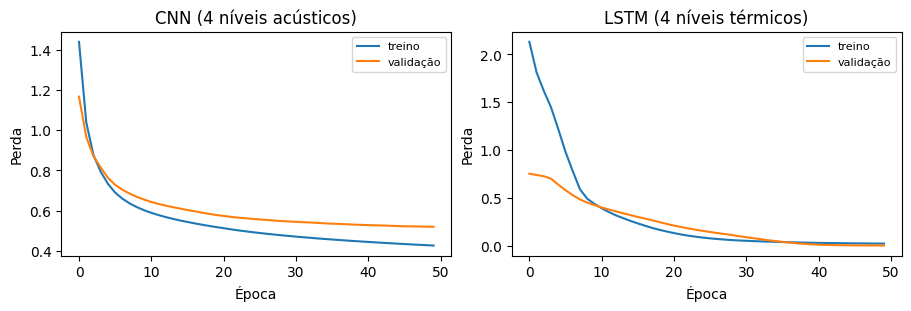

In [11]:
# 9. Curvas de treino
fig, ax = plt.subplots(1, 2, figsize=(9, 3), constrained_layout=True)
for a, h, t in [(ax[0], h_cnn, "CNN (4 níveis acústicos)"), (ax[1], h_lstm, "LSTM (4 níveis térmicos)")]:
    a.plot(h.history["loss"], label="treino"); a.plot(h.history["val_loss"], label="validação")
    a.set_title(t); a.set_xlabel("Época"); a.set_ylabel("Perda"); a.legend(fontsize=8)
plt.savefig(f"{SAIDA}/curvas_insitu.png", dpi=150); plt.show()

## Próximos passos

1. **Notebook 12**: avaliação nas sessões de teste (H1 e H2).
2. **Firmware**: a CNN passa a ter **4 saídas** (níveis acústicos) e a fusão passa a ser a **camada densa** do `fusao.json` (8 entradas, 4 saídas, 36 parâmetros). O `nivelAcustico()` e o `classePorRegra()` do firmware precisam ser trocados; o notebook 05 precisa gerar os novos `.h`. Conferir depois o tamanho na Flash (margem de 1,3 KB) e a latência no `Teste_Inferencia`.